<h1> SARSA

State - Action - Reward - State - Action

TD(0) and SARSA are both value-based learning methods.

The key point is that SARSA uses the actual next action—selected by the policy—for the update. For this reason, it is an on-policy algorithm.

It learns the state-action value function:

$\begin{aligned}
Q(s,a)\leftarrow Q(s,a)+\alpha [&r+\gamma Q(s',a')\\
&-Q(s,a)]
\end{aligned}$


Here, $a'$ is the action that the current policy selects in the next state. SARSA typically also improves the policy using these values.

#### Environment Selection

For the implementation, we use the `CliffWalking-v0` environment from Gymnasium. This environment is a GridWorld in which:
- The agent moves from a starting point toward a goal.
- Falling off the cliff incurs a heavy penalty.
- Every standard move also carries a cost.
- The agent must choose between a shorter, riskier path and a longer, safer one.

This environment is well-suited for a subsequent comparison between SARSA and Q-Learning.

In [214]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

import gymnasium as gym

<h3> Step 1: Creating and Examining the Environment

In [215]:
env = gym.make("CliffWalking-v1")

state, info = env.reset(seed=42)

print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
print("Initial state:", state)

print("Actions:")
print("0 = Up")
print("1 = Right")
print("2 = Down")
print("3 = Left")

Observation space: Discrete(48)
Action space: Discrete(4)
Initial state: 36
Actions:
0 = Up
1 = Right
2 = Down
3 = Left


The environment is a $4 \times 12$ grid, with states numbered from $0$ to $47$.
To convert a state number into row and column coordinates:

$\text{row} = \lfloor \text{state}/12 \rfloor$

$\text{col} = \text{state} \bmod 12$

For $\text{state} = 36$:

$\text{row} = 36 // 12 = 3$

$\text{col} = 36 \% 12 = 0$

Thus, state 36 corresponds to the start position, located in the last row and the first column.

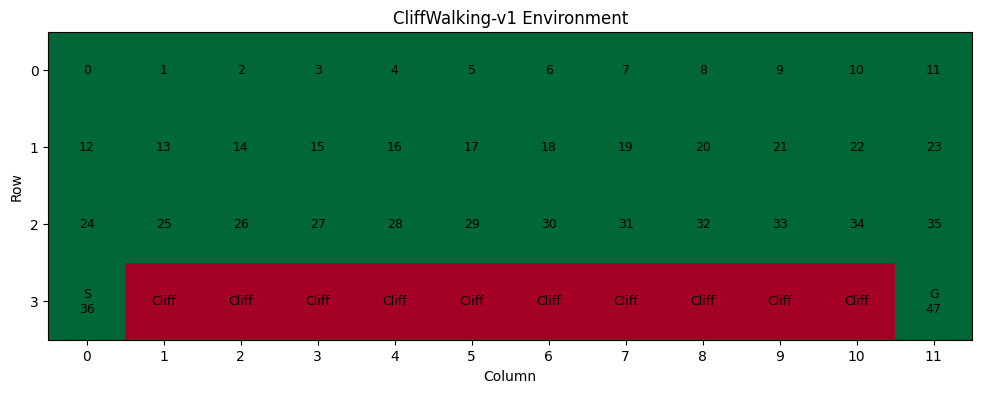

In [216]:
env_map = np.zeros((4, 12))

env_map[3, 1:11] = -1

plt.figure(figsize=(12, 4))
plt.imshow(env_map, cmap="RdYlGn", origin="upper")

for row in range(4):
    for col in range(12):
        state = row * 12 + col

        if row == 3 and col == 0:
            label = f"S\n{state}"
        elif row == 3 and col == 11:
            label = f"G\n{state}"
        elif row == 3 and 1 <= col <= 10:
            label = "Cliff"
        else:
            label = str(state)

        plt.text(col, row, label, ha="center", va="center",
                 color="black", fontsize=9)

plt.xticks(range(12))
plt.yticks(range(4))
plt.xlabel("Column")
plt.ylabel("Row")
plt.title("CliffWalking-v1 Environment")
plt.grid(False)
plt.show()

<h3> Step 2: Building the Q-table

In the CliffWalking-v1 environment, we have:
- 48 states
- 4 actions

Therefore, for each state, we must store the value of all 4 actions.

$Q(s,a)$


In [217]:
Q = np.zeros((
    env.observation_space.n,
    env.action_space.n
))

print("Q-table shape:", Q.shape)
print("Initial Q-values for state 36:", Q[36])

Q-table shape: (48, 4)
Initial Q-values for state 36: [0. 0. 0. 0.]


All values ​​are zero, because the agent has not yet undergone any training.

<h3> Step 3: ε-greedy implementation

This policy strikes a balance between two behaviors:
- Exploration: Selecting a random action to discover new paths.
- Exploitation: Selecting the action that has the best value in the Q-table.

To avoid initial bias, it is better to choose randomly among the best actions when the Q-values ​​are equal.

In [218]:
def epsilon_greedy(state, Q, epsilon=0.1):

    if np.random.random() < epsilon:
        return env.action_space.sample()

    best_actions = np.flatnonzero(
        Q[state] == np.max(Q[state])
    )

    return np.random.choice(best_actions)

Unlike Q-Learning, in SARSA we use the actual next action, not necessarily the best possible action.

<h3> Step 4: Policy Test

Since all Q-values ​​are currently zero, `np.argmax` will always select action 0—that is, "Up"—during the exploitation phase. Other choices may arise as a result of exploration.

In [219]:
# state = 36

# for _ in range(10):
#     action = epsilon_greedy(
#         state,
#         Q,
#         epsilon=0.1
#     )
#     print(action)

The output is always 0, because `np.argmax` returns the first index with the maximum value in the event of a tie.
Therefore, the agent has no actual reason to prefer "Up" over any other action; it simply selects it due to the way `argmax` is implemented.

Key point: At this stage, the agent has not yet learned that repeatedly colliding with a wall is undesirable. Once we train the model using SARSA, negative rewards will be incorporated into the Q-values, and the agent will gradually learn to select better actions.

#### Example of Different Choices

In [220]:
action_names = {
    0: "Up",
    1: "Right",
    2: "Down",
    3: "Left"
}

state, info = env.reset(seed=42)
env.action_space.seed(42)

path = [state]
total_reward = 0

for step in range(5):
    action = epsilon_greedy(
        state,
        Q,
        epsilon=0.1
    )

    next_state, reward, terminated, truncated, info = env.step(
        action
    )

    print(
        f"Step {step + 1}: "
        f"State {state} --{action_names[action]}--> "
        f"State {next_state} | Reward: {reward}"
    )

    path.append(next_state)
    total_reward += reward

    state = next_state

    if terminated or truncated:
        print("Episode finished!")
        break

print("\nActual path:", path)
print("Total reward:", total_reward)

Step 1: State 36 --Up--> State 24 | Reward: -1
Step 2: State 24 --Left--> State 24 | Reward: -1
Step 3: State 24 --Down--> State 36 | Reward: -1
Step 4: State 36 --Down--> State 36 | Reward: -1
Step 5: State 36 --Up--> State 24 | Reward: -1

Actual path: [36, 24, 24, 36, 36, 24]
Total reward: -5


<h3> Step 5: Implementation of the SARSA Algorithm

In [221]:
def train_sarsa(
    env,
    episodes=500,
    alpha=0.5,
    gamma=1.0,
    epsilon=0.1
):
    Q = np.zeros((
        env.observation_space.n,
        env.action_space.n
    ))

    episode_rewards = []
    episode_steps = []

    for _ in range(episodes):

        state, _ = env.reset()

        action = epsilon_greedy(
            state, Q, epsilon
        )

        total_reward = 0
        steps = 0

        while True:

            next_state, reward, terminated, truncated, _ = (
                env.step(action)
            )

            total_reward += reward
            steps += 1

            # If we have reached the goal, we no longer have a future.
            if terminated:
                td_target = reward

                Q[state, action] += alpha * (
                    td_target - Q[state, action]
                )

                break

            # Selecting the next action using the same ε-greedy policy
            next_action = epsilon_greedy(
                next_state, Q, epsilon
            )

            # SARSA Target
            td_target = (
                reward
                + gamma * Q[next_state, next_action]
            )

            # Q-value update
            Q[state, action] += alpha * (
                td_target - Q[state, action]
            )

            if truncated:
                break

            state = next_state
            action = next_action

        episode_rewards.append(total_reward)
        episode_steps.append(steps)

    return (
        Q,
        np.array(episode_rewards),
        np.array(episode_steps)
    )

<h3> Step 7: Agent Training

Parameters:

| Parameter | Value | Usage |
| ----- | ----- | ----- | 
| episodes | 500 | Number of training games |
| alpha | 0.5 | Learning rate |
| gamma | 1.0 | Importance of future rewards |
| epsilon | 0.1 | Probability of exploration |

In [222]:
np.random.seed(42)
env.action_space.seed(42)

Q_sarsa, episode_rewards, episode_steps = train_sarsa(
    env,
    episodes=500,
    alpha=0.5,
    gamma=1.0,
    epsilon=0.1
)

print("Q-table shape:", Q_sarsa.shape)

print(
    "Mean reward (first 50 episodes):",
    np.mean(episode_rewards[:50])
)

print(
    "Mean reward (last 50 episodes):",
    np.mean(episode_rewards[-50:])
)

print(
    "Mean steps (last 50 episodes):",
    np.mean(episode_steps[-50:])
)

Q-table shape: (48, 4)
Mean reward (first 50 episodes): -111.52
Mean reward (last 50 episodes): -22.9
Mean steps (last 50 episodes): 20.92


The results indicate that SARSA is learning, and the agent's performance has improved noticeably.

In CliffWalking, each move typically carries a reward of -1, while falling off the cliff incurs a penalty of -100. Therefore, a negative reward value is expected.

The key point is that the average reward has improved from -111.52 to -22.9; this indicates that the agent is learning to avoid high-cost paths. Of course, to verify the quality of the path, we should also examine the frequency of falling off the cliff.

<h3> Step 8: Plotting the SARSA Learning Curve

This chart displays both the reward for each episode and its moving average, in order to separate the overall trend from random fluctuations.

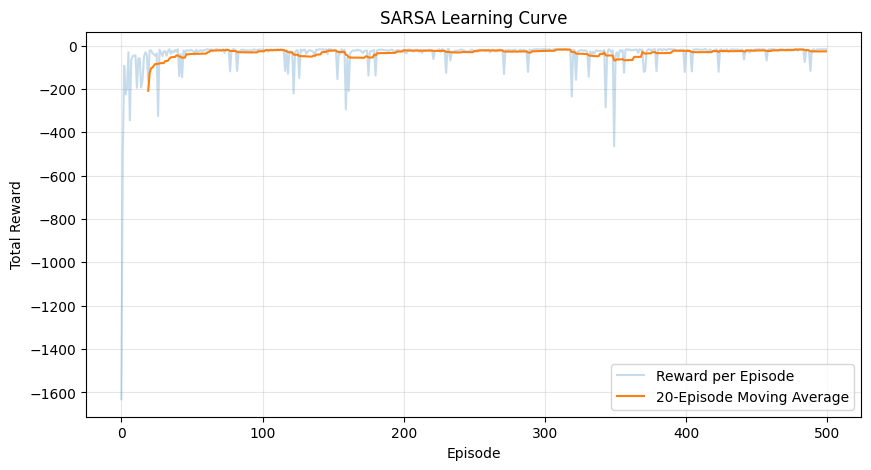

In [223]:
window = 20

moving_avg_rewards = np.convolve(
    episode_rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    episode_rewards,
    alpha=0.25,
    label="Reward per Episode"
)

plt.plot(
    np.arange(window - 1, len(episode_rewards)),
    moving_avg_rewards,
    label="20-Episode Moving Average"
)

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("SARSA Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A) Early Training Phase

In the initial episodes, the rewards are highly negative; in one instance, a value as low as -1630 is reached.
Why?
In the CliffWalking environment:
- Each standard move incurs a reward of -1.
- Falling off the cliff results in a penalty of -100.
- Falling off the cliff does not necessarily terminate the episode; 

the agent typically returns to the starting point and may repeat the same mistake.</br>
Consequently, during the early stages of training, the agent might fall off the cliff multiple times and traverse long, high-cost paths.

B) Progress During Training

The orange line trends upward from the beginning of the plot, shifting from highly negative values ​​to a range closer to -20 to -40.
This is a significant indicator: the agent is learning to follow paths with lower costs.</br>
However, occasional dips are still visible. For instance, around episodes 150 and 350, the moving average drops again.</br>
These dips could stem from exploration, falling off the cliff, or selecting high-cost paths. It is not possible to determine the exact cause of each drop based solely on the chart.

C) Has the Curve Converged?

In the final section, the moving average is relatively stable, yet it continues to fluctuate.
Therefore, it is more accurate to state that:
- Initial learning has been successful.
- Performance has improved and reached a state of relative stability.
- There is insufficient evidence to confirm convergence to an optimal policy.

Important Note: Since $\epsilon=0.1$ is used during training, the agent selects a random action 10% of the time. Thus, even if it has learned a strong policy, it may occasionally explore a suboptimal path.

<h3> Analyzing the number of moves

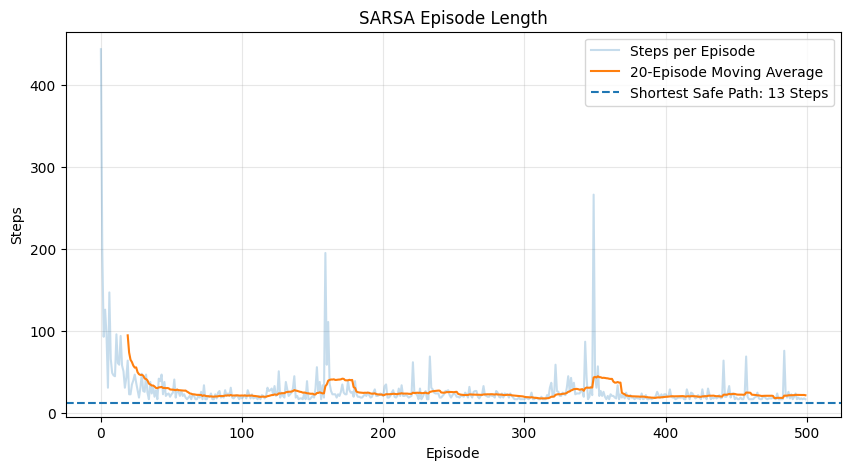

In [224]:
moving_avg_steps = np.convolve(
    episode_steps,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 5))

plt.plot(
    episode_steps,
    alpha=0.25,
    label="Steps per Episode"
)

plt.plot(
    np.arange(window - 1, len(episode_steps)),
    moving_avg_steps,
    label="20-Episode Moving Average"
)

plt.axhline(
    13,
    linestyle="--",
    label="Shortest Safe Path: 13 Steps"
)

plt.xlabel("Episode")
plt.ylabel("Steps")
plt.title("SARSA Episode Length")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A) Early Stage of Training

Initially, some episodes lasted for hundreds of steps.</br>
This behavior indicates that the agent has not yet fully learned the path to the goal; it may wander aimlessly or fall off the cliff multiple times.

B) Reduction in the Number of Steps

The moving average drops rapidly during the early stages of training and subsequently stabilizes, generally hovering between 20 and 30 steps.
This result aligns with the reward chart:
- Fewer steps typically incur lower step costs.
- Falling off the cliff less frequently reduces heavy penalties.
- More efficient paths lead to higher total rewards.

C) Why Do Spikes Occur?

Around episodes 160 and 350, significant spikes in the number of steps are observed.</br>
These spikes may stem from exploration or the agent venturing onto suboptimal paths. Since exploration remains active, such occurrences are natural during the training process.

D) Comparison with the Shortest Safe Path

The blue dashed line is positioned at 13 steps.</br>
This safe path consists of one move up, 11 moves to the right, and one move down to reach the goal—totaling 13 steps.</br>
The mean for the last 50 episodes is:

$\text{Mean Steps}=20.92$

This means that, on average, the agent still requires about 8 more steps than the shortest safe path.</br>
This discrepancy does not necessarily imply poor performance, as exploration is still ongoing and some episodes involve falling off the cliff. Nevertheless, it indicates that there is room for improvement.

### SARSA Learning Analysis

The SARSA agent was trained for 500 episodes in the `CliffWalking-v1` environment using an epsilon-greedy policy.

#### Results

| Metric | Result |
|---|---:|
| Mean reward — first 50 episodes | -111.52 |
| Mean reward — last 50 episodes | -22.90 |
| Mean steps — last 50 episodes | 20.92 |
| Shortest safe path | 13 steps |

#### Reward Analysis

The average reward improved substantially during training, indicating that the agent learned to reduce the cost of its actions and discover more effective routes.

Large negative rewards occurred during early training because the agent could repeatedly fall off the cliff, receiving a penalty of -100 for each fall. Occasional negative spikes persisted because epsilon-greedy exploration remained active.

#### Episode Length Analysis

The average episode length decreased considerably from its initial value. However, the final average of 20.92 steps remained above the 13-step shortest safe path, suggesting that the learned policy had not yet consistently reached the most efficient safe route.

#### Conclusion

The learning curves demonstrate meaningful progress in SARSA training. However, further evaluation is needed to determine how well the learned policy performs without exploration and whether it consistently follows an efficient route.

<h3> Step 9: Evaluation

During SARSA training, we do not always select the best action; instead, we use an ε-greedy policy. However, here we construct an evaluation function that always selects the current best action.

Now, we want to understand what the agent has actually learned—not just during training, but also when it is no longer required to select random actions for the sake of exploration.

In [225]:
def greedy_action(state, Q):
    best_actions = np.flatnonzero(
        Q[state] == np.max(Q[state])
    )

    return int(np.random.choice(best_actions))

If multiple actions share the same maximum Q-value, we choose randomly among them. This is done solely to break ties and does not constitute exploration.

In the following function, in addition to the reward and the number of moves, we also record the number of times the agent falls off the cliff and the goal-reaching rate.

In [226]:
def evaluate_sarsa(
    env,
    Q,
    episodes=1000,
    max_steps=1000
):
    rewards = []
    steps_history = []
    cliff_falls = []
    successes = []
    paths = []
    timeouts = 0

    for _ in range(episodes):
        state, _ = env.reset()

        total_reward = 0
        falls = 0
        path = [int(state)]
        reached_goal = False
        timed_out = False

        for step in range(max_steps):
            action = greedy_action(state, Q)

            next_state, reward, terminated, truncated, _ = (
                env.step(action)
            )

            total_reward += reward

            if reward == -100:
                falls += 1

            path.append(int(next_state))
            state = next_state

            if terminated:
                reached_goal = True
                break

            if truncated:
                timed_out = True
                break
        else:
            timed_out = True

        rewards.append(total_reward)
        steps_history.append(step + 1)
        cliff_falls.append(falls)
        successes.append(int(reached_goal))
        paths.append(path)

        if timed_out:
            timeouts += 1

    return {
        "rewards": np.array(rewards),
        "steps": np.array(steps_history),
        "cliff_falls": np.array(cliff_falls),
        "successes": np.array(successes),
        "paths": paths,
        "timeouts": timeouts
    }

If an episode reaches the `max_steps` limit, it is recorded as a timeout. This limit is in place to prevent the policy from potentially getting stuck in an infinite loop.

In [227]:
np.random.seed(42)

results = evaluate_sarsa(
    env,
    Q_sarsa,
    episodes=1000
)

print(
    "Mean reward:",
    np.mean(results["rewards"])
)

print(
    "Mean steps:",
    np.mean(results["steps"])
)

print(
    "Mean cliff falls per episode:",
    np.mean(results["cliff_falls"])
)

print(
    "Success rate:",
    np.mean(results["successes"])
)

print(
    "Timeout episodes:",
    results["timeouts"]
)

Mean reward: -17.0
Mean steps: 17.0
Mean cliff falls per episode: 0.0
Success rate: 1.0
Timeout episodes: 0


<h3> Step 10: Analyzing the Agent's actual path

In [228]:
path = results["paths"][0]

print("Path length:", len(path) - 1)
print("State path:", path[:40])

print(
    "Grid coordinates:",
    [divmod(state, 12) for state in path[:40]]
)

Path length: 17
State path: [36, 24, 12, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 23, 35, 47]
Grid coordinates: [(3, 0), (2, 0), (1, 0), (0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (0, 10), (0, 11), (1, 11), (2, 11), (3, 11)]


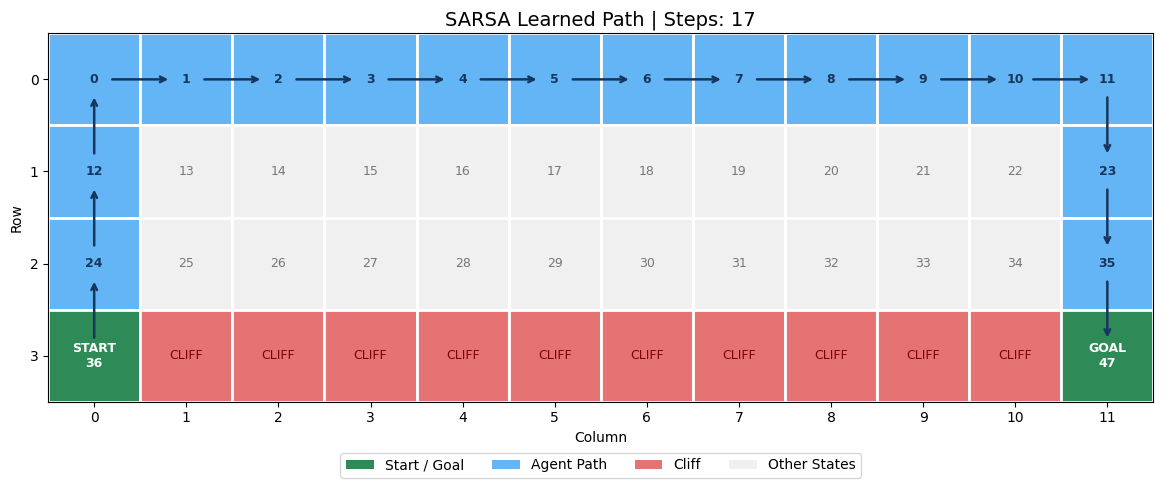

In [229]:
path = results["paths"][0]

fig, ax = plt.subplots(figsize=(15, 5))

route_states = set(path)

for state in range(48):
    row, col = divmod(state, 12)

    if state == 36 or state == 47:
        color = "#2E8B57"       # Start / Goal
    elif row == 3 and 0 < col < 11:
        color = "#E57373"       # Cliff
    elif state in route_states:
        color = "#64B5F6"       # Agent path
    else:
        color = "#F0F0F0"       # Other states

    ax.add_patch(
        Rectangle(
            (col, row), 1, 1,
            facecolor=color,
            edgecolor="white",
            linewidth=2
        )
    )

for current, next_state in zip(path[:-1], path[1:]):
    r1, c1 = divmod(current, 12)
    r2, c2 = divmod(next_state, 12)

    ax.annotate(
        "",
        xy=(c2 + 0.5, r2 + 0.5),
        xytext=(c1 + 0.5, r1 + 0.5),
        arrowprops=dict(
            arrowstyle="->",
            color="#17365D",
            linewidth=1.8,
            shrinkA=13,
            shrinkB=13
        )
    )

for state in range(48):
    row, col = divmod(state, 12)

    if state == 36:
        label = "START\n36"
        text_color = "white"
    elif state == 47:
        label = "GOAL\n47"
        text_color = "white"
    elif state in route_states:
        label = str(state)
        text_color = "#17365D"
    elif row == 3 and 0 < col < 11:
        label = "CLIFF"
        text_color = "#7F0000"
    else:
        label = str(state)
        text_color = "#777777"

    ax.text(
        col + 0.5,
        row + 0.5,
        label,
        ha="center",
        va="center",
        fontsize=9,
        fontweight="bold" if state in route_states else "normal",
        color=text_color
    )

ax.set_xlim(0, 12)
ax.set_ylim(4, 0)
ax.set_aspect("equal")

ax.set_xticks(np.arange(12) + 0.5)
ax.set_xticklabels(range(12))
ax.set_yticks(np.arange(4) + 0.5)
ax.set_yticklabels(range(4))

ax.set_xlabel("Column")
ax.set_ylabel("Row")
ax.set_title(
    f"SARSA Learned Path | Steps: {len(path) - 1}",
    fontsize=14
)

ax.legend(
    handles=[
        Patch(facecolor="#2E8B57", label="Start / Goal"),
        Patch(facecolor="#64B5F6", label="Agent Path"),
        Patch(facecolor="#E57373", label="Cliff"),
        Patch(facecolor="#F0F0F0", label="Other States")
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=4
)

plt.tight_layout()
plt.show()